In [35]:
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import nltk
from nltk.tokenize import word_tokenize
from nltk import pos_tag
import numpy as np

# Download required NLTK resources
try:
    nltk.data.find('tokenizers/punkt')
except LookupError:
    nltk.download('punkt')
try:
    nltk.data.find('tokenizers/punkt_tab')
except LookupError:
    nltk.download('punkt_tab')
try:
    nltk.data.find('taggers/averaged_perceptron_tagger')
except LookupError:
    nltk.download('averaged_perceptron_tagger')
try:
    nltk.data.find('taggers/averaged_perceptron_tagger_eng')
except LookupError:
    nltk.download('averaged_perceptron_tagger_eng')


# Load dataset
ds = load_dataset("surrey-nlp/BESSTIE-CW-26")

print("Dataset Overview:")
print(ds)


Dataset Overview:
DatasetDict({
    train: Dataset({
        features: ['text', 'variety', 'source', 'Sentiment', 'Sarcasm'],
        num_rows: 3747
    })
    validation: Dataset({
        features: ['text', 'variety', 'source', 'Sentiment', 'Sarcasm'],
        num_rows: 313
    })
    test: Dataset({
        features: ['text', 'variety', 'source', 'Sentiment', 'Sarcasm'],
        num_rows: 2183
    })
})


In [36]:
# print sample data
for i in range(3):
  print(ds['test'][i])


{'text': 'We are in the Yarra valley, we have a pair of butcher birds, who grace us with their presence. They call in for a cuppa and a tim tam, a little bit of cat food. We just love them.', 'variety': 'en-AU', 'source': 'Reddit', 'Sentiment': 1.0, 'Sarcasm': 0.0}
{'text': 'Been here twice and had a great time. Location is very convenient and had its own parking. Food was good too and restaurant has multiple areas to accommodate groups indoor and out on the lawn or roof garden. Highly recommended a visit.', 'variety': 'en-AU', 'source': 'Google', 'Sentiment': 1.0, 'Sarcasm': 0.0}
{'text': 'Was it a "core" or "non-core" commitment?\nThe point is that the Coalition\'s record on keeping promises is so bad that you simply can\'t believe it.', 'variety': 'en-AU', 'source': 'Reddit', 'Sentiment': 0.0, 'Sarcasm': 1.0}


In [37]:

# Prepare data for analysis - combine all splits
all_data = []
for split in ds.keys():
    for sample in ds[split]:
        all_data.append({
            'split': split,
            'variety': sample['variety'],
            'Sarcasm': sample['Sarcasm'],
            'Sentiment': sample['Sentiment'],
            'text': sample['text']
        })

df = pd.DataFrame(all_data)

print(f"Total samples: {len(df)}")
print(f"Splits: {df['split'].unique()}")
print(f"Varieties: {df['variety'].unique()}")

Total samples: 6243
Splits: ['train' 'validation' 'test']
Varieties: ['en-UK' 'en-AU' 'en-IN']


In [38]:
# ANALYSIS 1: Sarcasm Distribution by Variety


print("SARCASM DISTRIBUTION BY VARIETY:")
print("-" * 80)
sarcasm_by_variety = pd.crosstab(df['variety'], df['Sarcasm'], margins=True)
print(sarcasm_by_variety)
print("\nSarcasm Distribution (%):")
print(pd.crosstab(df['variety'], df['Sarcasm'], normalize='index') * 100)


SARCASM DISTRIBUTION BY VARIETY:
--------------------------------------------------------------------------------
Sarcasm   0.0  1.0   All
variety                 
en-AU    1346  561  1907
en-IN    2173  159  2332
en-UK    1851  153  2004
All      5370  873  6243

Sarcasm Distribution (%):
Sarcasm        0.0        1.0
variety                      
en-AU    70.582066  29.417934
en-IN    93.181818   6.818182
en-UK    92.365269   7.634731


In [39]:
# ANALYSIS 2: Sentiment Distribution by Variety

print("SENTIMENT DISTRIBUTION BY VARIETY:")
print("-" * 80)
sentiment_by_variety = pd.crosstab(df['variety'], df['Sentiment'], margins=True)
print(sentiment_by_variety)
print("\nSentiment Distribution (%):")
print(pd.crosstab(df['variety'], df['Sentiment'], normalize='index') * 100)
print()

SENTIMENT DISTRIBUTION BY VARIETY:
--------------------------------------------------------------------------------
Sentiment   0.0   1.0   All
variety                    
en-AU      1030   877  1907
en-IN      1183  1149  2332
en-UK       971  1033  2004
All        3184  3059  6243

Sentiment Distribution (%):
Sentiment        0.0        1.0
variety                        
en-AU      54.011536  45.988464
en-IN      50.728988  49.271012
en-UK      48.453094  51.546906



In [40]:
# ANALYSIS 3: Distribution by Split

print("SARCASM AND SENTIMENT DISTRIBUTION BY SPLIT:")
print("-" * 80)
sarcasm_by_split = pd.crosstab(df['split'], df['Sarcasm'], margins=True)
sentiment_by_split = pd.crosstab(df['split'], df['Sentiment'], margins=True)
print("\nSarcasm by Split:")
print(sarcasm_by_split)
print("\nSentiment by Split:")
print(sentiment_by_split)
print()

SARCASM AND SENTIMENT DISTRIBUTION BY SPLIT:
--------------------------------------------------------------------------------

Sarcasm by Split:
Sarcasm      0.0  1.0   All
split                      
test        1878  305  2183
train       3223  524  3747
validation   269   44   313
All         5370  873  6243

Sentiment by Split:
Sentiment    0.0   1.0   All
split                       
test        1117  1066  2183
train       1907  1840  3747
validation   160   153   313
All         3184  3059  6243



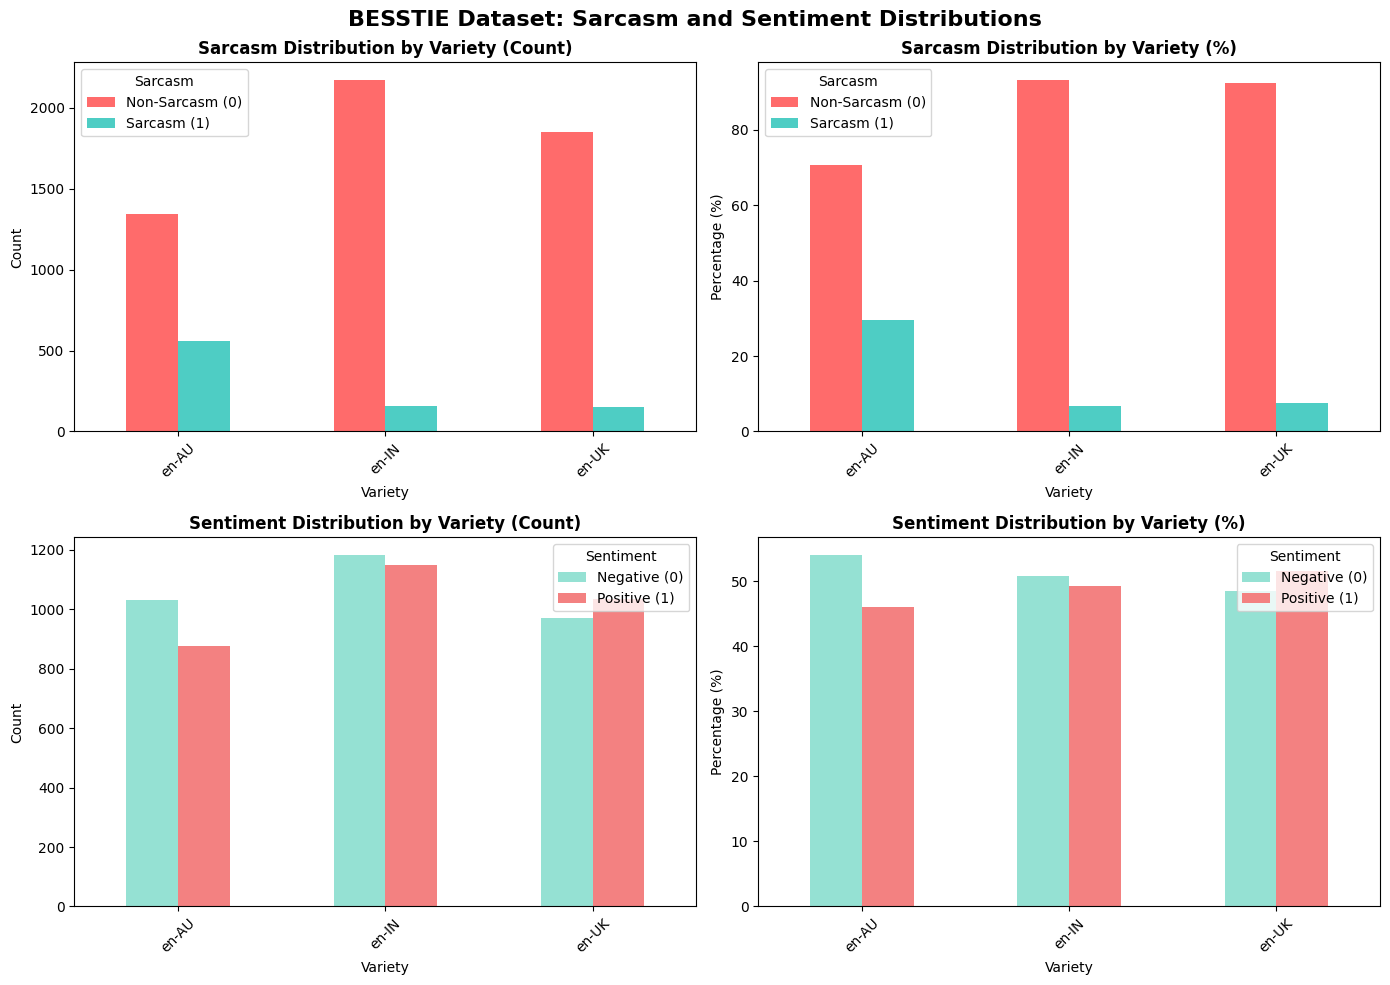

In [41]:
# VISUALIZATION 1: Sarcasm Distribution by Variety

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('BESSTIE Dataset: Sarcasm and Sentiment Distributions', fontsize=16, fontweight='bold')

# Sarcasm by Variety - Count
ax1 = axes[0, 0]
sarcasm_counts = df.groupby(['variety', 'Sarcasm']).size().unstack()
sarcasm_counts.plot(kind='bar', ax=ax1, color=['#FF6B6B', '#4ECDC4'])

ax1.set_title('Sarcasm Distribution by Variety (Count)', fontweight='bold')
ax1.set_ylabel('Count')
ax1.set_xlabel('Variety')
ax1.legend(title='Sarcasm', labels=['Non-Sarcasm (0)', 'Sarcasm (1)'])
ax1.tick_params(axis='x', rotation=45)

# Sarcasm by Variety - Percentage
ax2 = axes[0, 1]
sarcasm_pct = df.groupby(['variety', 'Sarcasm']).size().unstack(fill_value=0)
sarcasm_pct = sarcasm_pct.div(sarcasm_pct.sum(axis=1), axis=0) * 100
sarcasm_pct.plot(kind='bar', ax=ax2, color=['#FF6B6B', '#4ECDC4'], stacked=False)
ax2.set_title('Sarcasm Distribution by Variety (%)', fontweight='bold')
ax2.set_ylabel('Percentage (%)')
ax2.set_xlabel('Variety')
ax2.legend(title='Sarcasm', labels=['Non-Sarcasm (0)', 'Sarcasm (1)'])
ax2.tick_params(axis='x', rotation=45)

# Sentiment by Variety - Count
ax3 = axes[1, 0]
sentiment_counts = df.groupby(['variety', 'Sentiment']).size().unstack()
sentiment_counts.plot(kind='bar', ax=ax3, color=['#95E1D3', '#F38181'])
ax3.set_title('Sentiment Distribution by Variety (Count)', fontweight='bold')
ax3.set_ylabel('Count')
ax3.set_xlabel('Variety')
ax3.legend(title='Sentiment', labels=['Negative (0)', 'Positive (1)'])
ax3.tick_params(axis='x', rotation=45)

# Sentiment by Variety - Percentage
ax4 = axes[1, 1]
sentiment_pct = df.groupby(['variety', 'Sentiment']).size().unstack(fill_value=0)
sentiment_pct = sentiment_pct.div(sentiment_pct.sum(axis=1), axis=0) * 100
sentiment_pct.plot(kind='bar', ax=ax4, color=['#95E1D3', '#F38181'], stacked=False)
ax4.set_title('Sentiment Distribution by Variety (%)', fontweight='bold')
ax4.set_ylabel('Percentage (%)')
ax4.set_xlabel('Variety')
ax4.legend(title='Sentiment', labels=['Negative (0)', 'Positive (1)'])
ax4.tick_params(axis='x', rotation=45)

plt.tight_layout()
# plt.close()

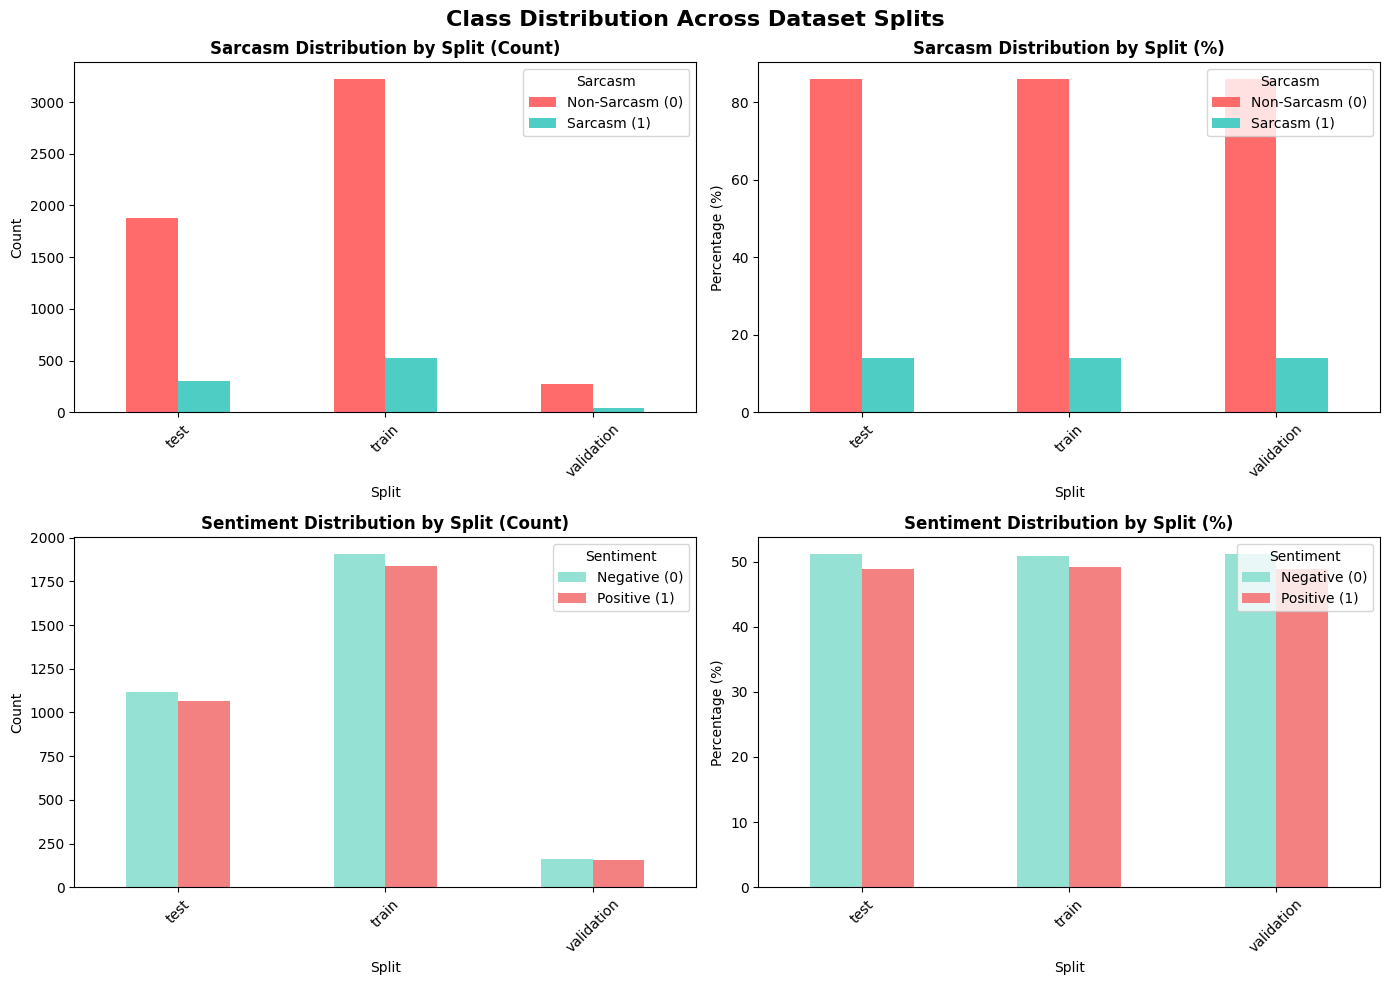

In [42]:
# VISUALIZATION 2: Distribution by Split

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Class Distribution Across Dataset Splits', fontsize=16, fontweight='bold')

# Sarcasm by Split - Count
ax1 = axes[0, 0]
sarcasm_split = df.groupby(['split', 'Sarcasm']).size().unstack()
sarcasm_split.plot(kind='bar', ax=ax1, color=['#FF6B6B', '#4ECDC4'])
ax1.set_title('Sarcasm Distribution by Split (Count)', fontweight='bold')
ax1.set_ylabel('Count')
ax1.set_xlabel('Split')
ax1.legend(title='Sarcasm', labels=['Non-Sarcasm (0)', 'Sarcasm (1)'])
ax1.tick_params(axis='x', rotation=45)

# Sarcasm by Split - Percentage
ax2 = axes[0, 1]
sarcasm_split_pct = df.groupby(['split', 'Sarcasm']).size().unstack(fill_value=0)
sarcasm_split_pct = sarcasm_split_pct.div(sarcasm_split_pct.sum(axis=1), axis=0) * 100
sarcasm_split_pct.plot(kind='bar', ax=ax2, color=['#FF6B6B', '#4ECDC4'], stacked=False)
ax2.set_title('Sarcasm Distribution by Split (%)', fontweight='bold')
ax2.set_ylabel('Percentage (%)')
ax2.set_xlabel('Split')
ax2.legend(title='Sarcasm', labels=['Non-Sarcasm (0)', 'Sarcasm (1)'])
ax2.tick_params(axis='x', rotation=45)

# Sentiment by Split - Count
ax3 = axes[1, 0]
sentiment_split = df.groupby(['split', 'Sentiment']).size().unstack()
sentiment_split.plot(kind='bar', ax=ax3, color=['#95E1D3', '#F38181'])
ax3.set_title('Sentiment Distribution by Split (Count)', fontweight='bold')
ax3.set_ylabel('Count')
ax3.set_xlabel('Split')
ax3.legend(title='Sentiment', labels=['Negative (0)', 'Positive (1)'])
ax3.tick_params(axis='x', rotation=45)

# Sentiment by Split - Percentage
ax4 = axes[1, 1]
sentiment_split_pct = df.groupby(['split', 'Sentiment']).size().unstack(fill_value=0)
sentiment_split_pct = sentiment_split_pct.div(sentiment_split_pct.sum(axis=1), axis=0) * 100
sentiment_split_pct.plot(kind='bar', ax=ax4, color=['#95E1D3', '#F38181'], stacked=False)
ax4.set_title('Sentiment Distribution by Split (%)', fontweight='bold')
ax4.set_ylabel('Percentage (%)')
ax4.set_xlabel('Split')
ax4.legend(title='Sentiment', labels=['Negative (0)', 'Positive (1)'])
ax4.tick_params(axis='x', rotation=45)

plt.tight_layout()



In [43]:
def extract_pos_counts(text):
    """
    Extract counts of the four major POS tags from text.

    Args:
        text (str): Input text to analyze
    Returns:
        dict: Dictionary with counts for Noun, Verb, Adjective, Adverb
    """
    try:
        tokens = word_tokenize(text.lower())
        pos_tags = pos_tag(tokens)

        # Count the four major POS tags
        pos_counts = {'Noun': 0, 'Verb': 0, 'Adjective': 0, 'Adverb': 0}

        for word, tag in pos_tags:
            # NN, NNS, NNP, NNPS for nouns
            if tag.startswith('NN'):
                pos_counts['Noun'] += 1
            # VB, VBD, VBG, VBN, VBP, VBZ for verbs
            elif tag.startswith('VB'):
                pos_counts['Verb'] += 1
            # JJ, JJR, JJS for adjectives
            elif tag.startswith('JJ'):
                pos_counts['Adjective'] += 1
            # RB, RBR, RBS for adverbs
            elif tag.startswith('RB'):
                pos_counts['Adverb'] += 1

        return pos_counts
    except Exception as e:
        print(f"Error processing text: {e}")
        return {'Noun': 0, 'Verb': 0, 'Adjective': 0, 'Adverb': 0}

In [44]:
# Apply POS tagging to all documents
print("Extracting POS tags from documents...")
pos_data = df['text'].apply(extract_pos_counts)
pos_df = pd.DataFrame(pos_data.tolist())

# Combine POS counts with original data
df = pd.concat([df, pos_df], axis=1)
print(f"✓ POS tagging complete. Dataset shape: {df.shape}\n")

Extracting POS tags from documents...
✓ POS tagging complete. Dataset shape: (6243, 9)



In [45]:
# POS DISTRIBUTION STATISTICS - across 4 main POS Noun, Verb, Adj, Adv

print("POS TAG STATISTICS:")
print("-" * 80)
pos_stats = df[['Noun', 'Verb', 'Adjective', 'Adverb']].describe()
print(pos_stats)
print()

print("\nAVERAGE POS TAG COUNTS PER DOCUMENT:")
print("-" * 80)
avg_pos = df[['Noun', 'Verb', 'Adjective', 'Adverb']].mean()
print(f"Noun (NN):      {avg_pos['Noun']:.2f}")
print(f"Verb (VB):      {avg_pos['Verb']:.2f}")
print(f"Adjective (JJ): {avg_pos['Adjective']:.2f}")
print(f"Adverb (RB):    {avg_pos['Adverb']:.2f}")
print()

print("\nPOS TAG STATISTICS BY VARIETY:")
print("-" * 80)
pos_by_variety = df.groupby('variety')[['Noun', 'Verb', 'Adjective', 'Adverb']].agg(['mean', 'std'])
print(pos_by_variety)


POS TAG STATISTICS:
--------------------------------------------------------------------------------
              Noun         Verb    Adjective       Adverb
count  6243.000000  6243.000000  6243.000000  6243.000000
mean     13.117572     9.477014     5.732821     3.957392
std      16.405359    11.603120     6.766916     4.846484
min       0.000000     0.000000     0.000000     0.000000
25%       5.000000     3.000000     2.000000     1.000000
50%       9.000000     6.000000     4.000000     3.000000
75%      16.000000    12.000000     8.000000     5.000000
max     390.000000   201.000000   171.000000    91.000000


AVERAGE POS TAG COUNTS PER DOCUMENT:
--------------------------------------------------------------------------------
Noun (NN):      13.12
Verb (VB):      9.48
Adjective (JJ): 5.73
Adverb (RB):    3.96


POS TAG STATISTICS BY VARIETY:
--------------------------------------------------------------------------------
              Noun                  Verb            Adject

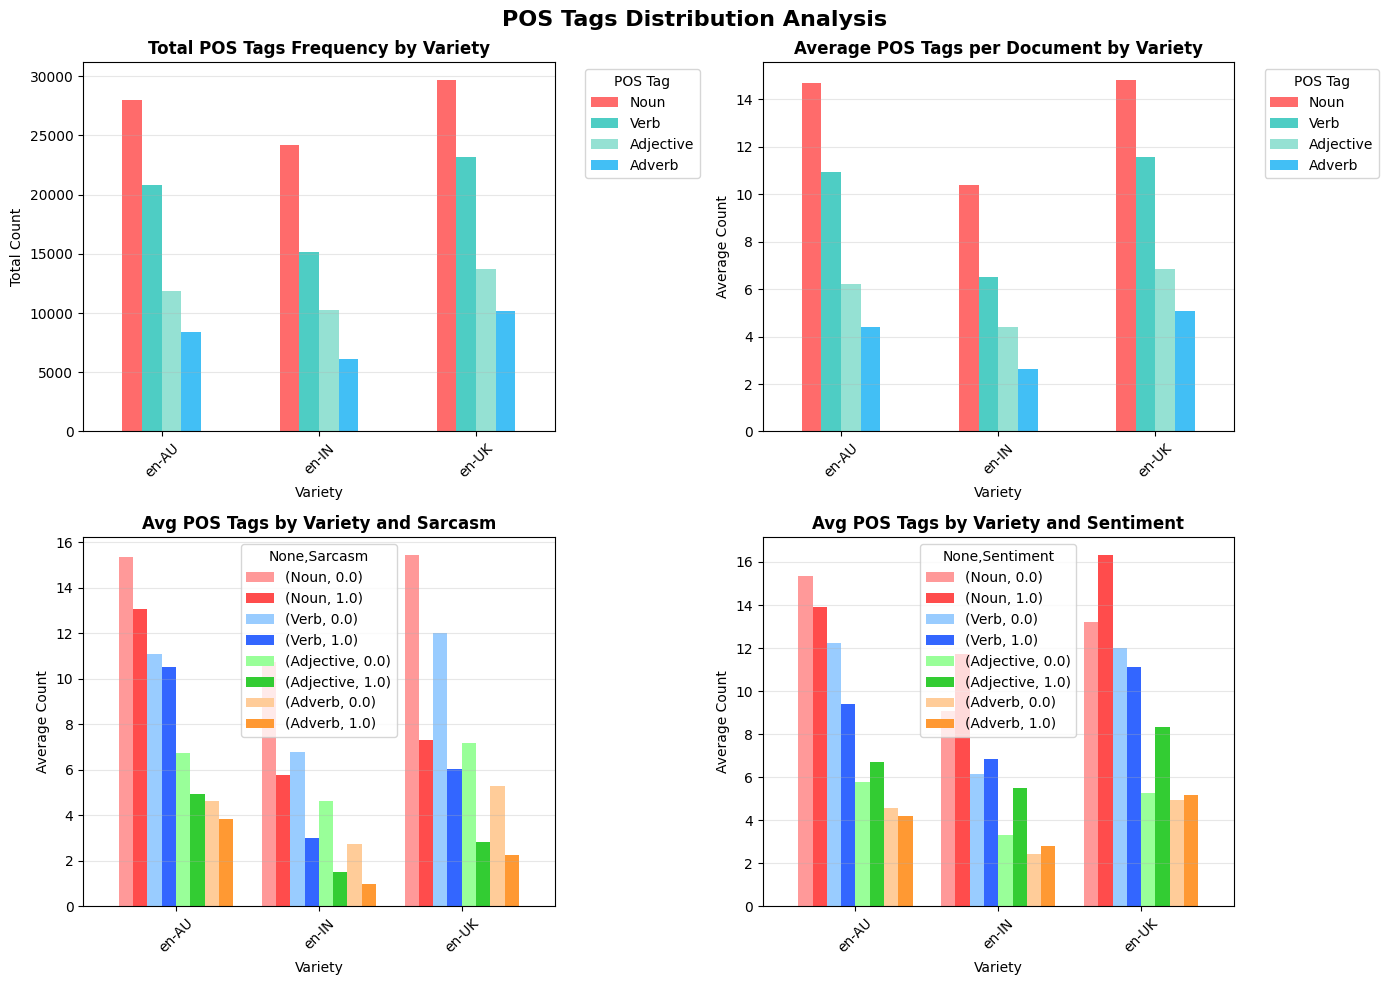

In [46]:
# POS DISTRIBUTION VISUALIZATIONS

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('POS Tags Distribution Analysis', fontsize=16, fontweight='bold')

pos_tags = ['Noun', 'Verb', 'Adjective', 'Adverb']
colors = ['#FF6B6B', '#4ECDC4', '#95E1D3', '#42BFF5']
colors_8 = ['#FF9999', '#FF4C4C', '#99CCFF', '#3366FF', '#99FF99', '#33CC33', '#FFCC99', '#FF9933']

# 1. Total POS counts by Variety (Bar Chart)
ax1 = axes[0, 0]
pos_counts_by_variety = df.groupby('variety')[['Noun', 'Verb', 'Adjective', 'Adverb']].sum()
pos_counts_by_variety.plot(kind='bar', ax=ax1, color=colors)
ax1.set_title('Total POS Tags Frequency by Variety', fontweight='bold')
ax1.set_ylabel('Total Count')
ax1.set_xlabel('Variety')
ax1.legend(title='POS Tag', bbox_to_anchor=(1.05, 1), loc='upper left')
ax1.tick_params(axis='x', rotation=45)
ax1.grid(axis='y', alpha=0.3)

# 2. Average POS counts per document by Variety (Bar Chart)
ax2 = axes[0, 1]
pos_avg_by_variety = df.groupby('variety')[['Noun', 'Verb', 'Adjective', 'Adverb']].mean()
pos_avg_by_variety.plot(kind='bar', ax=ax2, color=colors)
ax2.set_title('Average POS Tags per Document by Variety', fontweight='bold')
ax2.set_ylabel('Average Count')
ax2.set_xlabel('Variety')
ax2.legend(title='POS Tag', bbox_to_anchor=(1.05, 1), loc='upper left')
ax2.tick_params(axis='x', rotation=45)
ax2.grid(axis='y', alpha=0.3)

# 3. POS Distribution by Variety and Sarcasm
ax3 = axes[1, 0]
sarcasm_pos = df.groupby(['variety', 'Sarcasm'])[['Noun', 'Verb', 'Adjective', 'Adverb']].mean()
sarcasm_pos.unstack(level=1).plot(kind='bar', ax=ax3, color=colors_8, width=0.8)
ax3.set_title('Avg POS Tags by Variety and Sarcasm', fontweight='bold')
ax3.set_ylabel('Average Count')
ax3.set_xlabel('Variety')
ax3.tick_params(axis='x', rotation=45)
ax3.grid(axis='y', alpha=0.3)

# 4. POS Distribution by Variety and Sentiment
ax4 = axes[1, 1]
sentiment_pos = df.groupby(['variety', 'Sentiment'])[['Noun', 'Verb', 'Adjective', 'Adverb']].mean()
sentiment_pos.unstack(level=1).plot(kind='bar', ax=ax4, color=colors_8, width=0.8)
ax4.set_title('Avg POS Tags by Variety and Sentiment', fontweight='bold')
ax4.set_ylabel('Average Count')
ax4.set_xlabel('Variety')
ax4.tick_params(axis='x', rotation=45)
ax4.grid(axis='y', alpha=0.3)

plt.tight_layout()
